## Lab 2
### Part 2: Dealing with overfitting

Today we work with [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist) (*hint: it is available in `torchvision`*).

Your goal for today:
1. Train a FC (fully-connected) network that achieves >= 0.885 test accuracy.
2. Cause considerable overfitting by modifying the network (e.g. increasing the number of network parameters and/or layers) and demonstrate in in the appropriate way (e.g. plot loss and accurasy on train and validation set w.r.t. network complexity).
3. Try to deal with overfitting (at least partially) by using regularization techniques (Dropout/Batchnorm/...) and demonstrate the results.

__Please, write a small report describing your ideas, tries and achieved results in the end of this file.__

*Note*: Tasks 2 and 3 are interrelated, in task 3 your goal is to make the network from task 2 less prone to overfitting. Task 1 is independent from 2 and 3.

*Note 2*: We recomment to use Google Colab or other machine with GPU acceleration.

In [21]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torchsummary
from IPython.display import clear_output
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure
import numpy as np
import os


device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

In [22]:
# Technical function
def mkdir(path):
    if not os.path.exists(root_path):
        os.mkdir(root_path)
        print('Directory', path, 'is created!')
    else:
        print('Directory', path, 'already exists!')

root_path = 'fmnist'
mkdir(root_path)

Directory fmnist already exists!


In [23]:
download = True
train_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()
transforms.Compose((transforms.ToTensor()))


fmnist_dataset_train = torchvision.datasets.FashionMNIST(root_path,
                                                        train=True,
                                                        transform=train_transform,
                                                        target_transform=None,
                                                        download=download)
fmnist_dataset_test = torchvision.datasets.FashionMNIST(root_path,
                                                       train=False,
                                                       transform=test_transform,
                                                       target_transform=None,
                                                       download=download)

In [24]:
train_loader = torch.utils.data.DataLoader(fmnist_dataset_train,
                                           batch_size=128,
                                           shuffle=True,
                                           num_workers=2)
test_loader = torch.utils.data.DataLoader(fmnist_dataset_test,
                                          batch_size=256,
                                          shuffle=False,
                                          num_workers=2)

In [25]:
len(fmnist_dataset_test)

10000

In [26]:
for img, label in train_loader:
    print(img.shape)
#     print(img)
    print(label.shape)
    print(label.size(0))
    break

torch.Size([128, 1, 28, 28])
torch.Size([128])
128


### Task 1
Train a network that achieves $\geq 0.885$ test accuracy. It's fine to use only Linear (`nn.Linear`) layers and activations/dropout/batchnorm. Convolutional layers might be a great use, but we will meet them a bit later.

In [27]:
class TinyNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1):
        super(self.__class__, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(), # This layer converts image into a vector to use Linear layers afterwards
            # Your network structure comes here
            nn.Linear(input_shape, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, inp):
        out = self.model(inp)
        return out

In [28]:
torchsummary.summary(TinyNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
            Linear-2                 [-1, 1024]         803,840
              ReLU-3                 [-1, 1024]               0
            Linear-4                  [-1, 512]         524,800
              ReLU-5                  [-1, 512]               0
            Linear-6                  [-1, 256]         131,328
              ReLU-7                  [-1, 256]               0
            Linear-8                   [-1, 10]           2,570
Total params: 1,462,538
Trainable params: 1,462,538
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.03
Params size (MB): 5.58
Estimated Total Size (MB): 5.62
----------------------------------------------------------------


Your experiments come here:

Epoch 01: train acc=0.8111, test acc=0.8552
Epoch 02: train acc=0.8640, test acc=0.8561
Epoch 03: train acc=0.8814, test acc=0.8680
Epoch 04: train acc=0.8871, test acc=0.8771
Epoch 05: train acc=0.8967, test acc=0.8815
Epoch 06: train acc=0.8994, test acc=0.8737
Epoch 07: train acc=0.9054, test acc=0.8824
Epoch 08: train acc=0.9101, test acc=0.8842
Epoch 09: train acc=0.9127, test acc=0.8899
Epoch 10: train acc=0.9181, test acc=0.8831
Epoch 11: train acc=0.9196, test acc=0.8858
Epoch 12: train acc=0.9257, test acc=0.8805
Epoch 13: train acc=0.9241, test acc=0.8931
Epoch 14: train acc=0.9304, test acc=0.8926
Epoch 15: train acc=0.9314, test acc=0.8947
Epoch 16: train acc=0.9335, test acc=0.8964
Epoch 17: train acc=0.9384, test acc=0.8926
Epoch 18: train acc=0.9388, test acc=0.8946
Epoch 19: train acc=0.9411, test acc=0.8948
Epoch 20: train acc=0.9426, test acc=0.8945
Epoch 21: train acc=0.9459, test acc=0.8941
Epoch 22: train acc=0.9463, test acc=0.8910
Epoch 23: train acc=0.9493, test

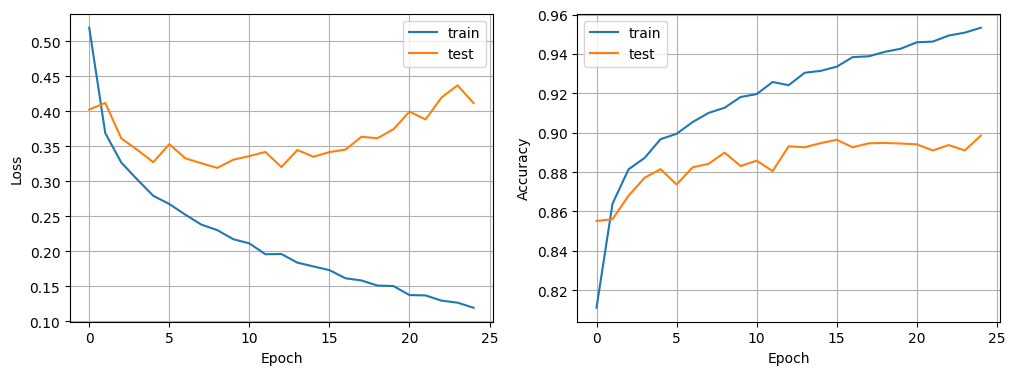

In [ ]:
model = TinyNeuralNetwork().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3) # YOUR CODE HERE
loss_func = nn.CrossEntropyLoss() # YOUR CODE HERE

# Your experiments, training and validation loops here
num_epochs = 25
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(num_epochs):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        opt.zero_grad()
        logits = model(images)
        loss = loss_func(logits, labels)
        loss.backward()
        opt.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    train_losses.append(total_loss / total)
    train_accs.append(correct / total)

    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += loss_func(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    test_losses.append(total_loss / total)
    test_accs.append(correct / total)
    print(f'Epoch {epoch+1:02d}: train acc={train_accs[-1]:.4f}, test acc={test_accs[-1]:.4f}')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='train')
plt.plot(test_losses, label='test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='train')
plt.plot(test_accs, label='test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend();
plt.grid()

plt.show()

### Task 2: Overfit it.
Build a network that will overfit to this dataset. Demonstrate the overfitting in the appropriate way (e.g. plot loss and accurasy on train and test set w.r.t. network complexity).

*Note:* you also might decrease the size of `train` dataset to enforce the overfitting and speed up the computations.

In [30]:
class OverfittingNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1):
        super(self.__class__, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(), # This layer converts image into a vector to use Linear layers afterwards
            # Your network structure comes here
            nn.Linear(input_shape, 2048),
            nn.ReLU(),
            nn.Linear(2048, 2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes)
        )

    def forward(self, inp):
        out = self.model(inp)
        return out

In [31]:
torchsummary.summary(OverfittingNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
            Linear-2                 [-1, 2048]       1,607,680
              ReLU-3                 [-1, 2048]               0
            Linear-4                 [-1, 2048]       4,196,352
              ReLU-5                 [-1, 2048]               0
            Linear-6                 [-1, 1024]       2,098,176
              ReLU-7                 [-1, 1024]               0
            Linear-8                  [-1, 512]         524,800
              ReLU-9                  [-1, 512]               0
           Linear-10                   [-1, 10]           5,130
Total params: 8,432,138
Trainable params: 8,432,138
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.09
Params size (MB): 32.17
Estima

Epoch 01: train acc=0.5676, test acc=0.6961
Epoch 02: train acc=0.7808, test acc=0.7649
Epoch 03: train acc=0.8308, test acc=0.7212
Epoch 04: train acc=0.8236, test acc=0.7643
Epoch 05: train acc=0.8492, test acc=0.8134
Epoch 06: train acc=0.8598, test acc=0.7799
Epoch 07: train acc=0.8678, test acc=0.7714
Epoch 08: train acc=0.8780, test acc=0.8157
Epoch 09: train acc=0.8762, test acc=0.8012
Epoch 10: train acc=0.8736, test acc=0.8248
Epoch 11: train acc=0.8826, test acc=0.8188
Epoch 12: train acc=0.8954, test acc=0.8273
Epoch 13: train acc=0.9058, test acc=0.8283
Epoch 14: train acc=0.9134, test acc=0.8291
Epoch 15: train acc=0.9110, test acc=0.7989
Epoch 16: train acc=0.8946, test acc=0.8403
Epoch 17: train acc=0.9182, test acc=0.8356
Epoch 18: train acc=0.9248, test acc=0.8192
Epoch 19: train acc=0.9184, test acc=0.8118
Epoch 20: train acc=0.9116, test acc=0.8072
Epoch 21: train acc=0.9268, test acc=0.8262
Epoch 22: train acc=0.9278, test acc=0.8012
Epoch 23: train acc=0.9252, test

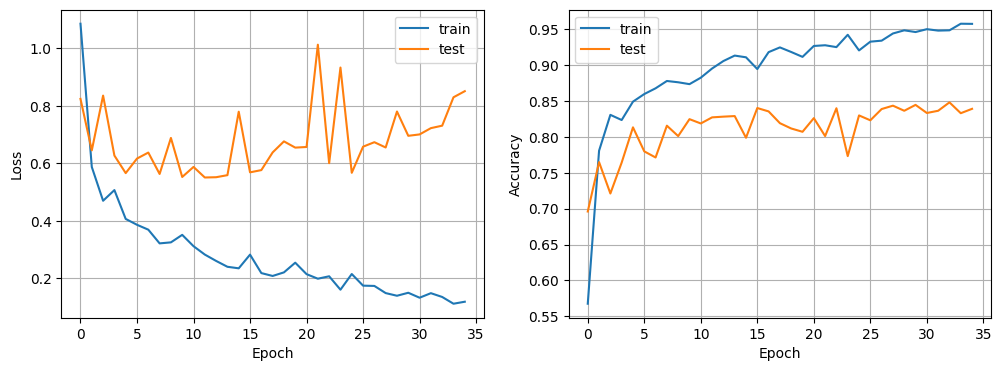

In [ ]:
model = OverfittingNeuralNetwork().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3) # YOUR CODE HERE
loss_func = nn.CrossEntropyLoss() # YOUR CODE HERE

# Your experiments, come
small_train = torch.utils.data.Subset(fmnist_dataset_train, range(5000))
small_loader = torch.utils.data.DataLoader(small_train, batch_size=128, shuffle=True)
num_epochs = 35
train_losses_overfit, test_losses_overfit = [], []
train_accs_overfit, test_accs_overfit = [], []

for epoch in range(num_epochs):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in small_loader:
        images, labels = images.to(device), labels.to(device)
        opt.zero_grad()
        logits = model(images)
        loss = loss_func(logits, labels)
        loss.backward()
        opt.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    train_losses_overfit.append(total_loss / total)
    train_accs_overfit.append(correct / total)

    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += loss_func(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    test_losses_overfit.append(total_loss / total)
    test_accs_overfit.append(correct / total)
    print(f'Epoch {epoch+1:02d}: train acc={train_accs_overfit[-1]:.4f}, test acc={test_accs_overfit[-1]:.4f}')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses_overfit, label='train')
plt.plot(test_losses_overfit, label='test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(train_accs_overfit, label='train')
plt.plot(test_accs_overfit, label='test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

### Task 3: Fix it.
Fix the overfitted network from the previous step (at least partially) by using regularization techniques (Dropout/Batchnorm/...) and demonstrate the results.

In [33]:
class FixedNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1):
        super(self.__class__, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(), # This layer converts image into a vector to use Linear layers afterwards
            # Your network structure comes here
            nn.Linear(input_shape, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, inp):
        out = self.model(inp)
        return out

In [34]:
torchsummary.summary(FixedNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
            Linear-2                 [-1, 1024]         803,840
       BatchNorm1d-3                 [-1, 1024]           2,048
              ReLU-4                 [-1, 1024]               0
           Dropout-5                 [-1, 1024]               0
            Linear-6                 [-1, 1024]       1,049,600
       BatchNorm1d-7                 [-1, 1024]           2,048
              ReLU-8                 [-1, 1024]               0
           Dropout-9                 [-1, 1024]               0
           Linear-10                  [-1, 512]         524,800
      BatchNorm1d-11                  [-1, 512]           1,024
             ReLU-12                  [-1, 512]               0
          Dropout-13                  [-1, 512]               0
           Linear-14                   

Epoch 01: train acc=0.6992, test acc=0.7898
Epoch 02: train acc=0.7994, test acc=0.8001
Epoch 03: train acc=0.8280, test acc=0.8180
Epoch 04: train acc=0.8480, test acc=0.8205
Epoch 05: train acc=0.8506, test acc=0.8206
Epoch 06: train acc=0.8612, test acc=0.8268
Epoch 07: train acc=0.8654, test acc=0.8267
Epoch 08: train acc=0.8682, test acc=0.8370
Epoch 09: train acc=0.8712, test acc=0.8321
Epoch 10: train acc=0.8704, test acc=0.8395
Epoch 11: train acc=0.8798, test acc=0.8252
Epoch 12: train acc=0.8770, test acc=0.8373
Epoch 13: train acc=0.8842, test acc=0.8240
Epoch 14: train acc=0.8794, test acc=0.8357
Epoch 15: train acc=0.8820, test acc=0.8125
Epoch 16: train acc=0.8822, test acc=0.8385
Epoch 17: train acc=0.8874, test acc=0.8420
Epoch 18: train acc=0.8978, test acc=0.8428
Epoch 19: train acc=0.9030, test acc=0.8335
Epoch 20: train acc=0.9082, test acc=0.8461
Epoch 21: train acc=0.9054, test acc=0.8304
Epoch 22: train acc=0.9114, test acc=0.8426
Epoch 23: train acc=0.9120, test

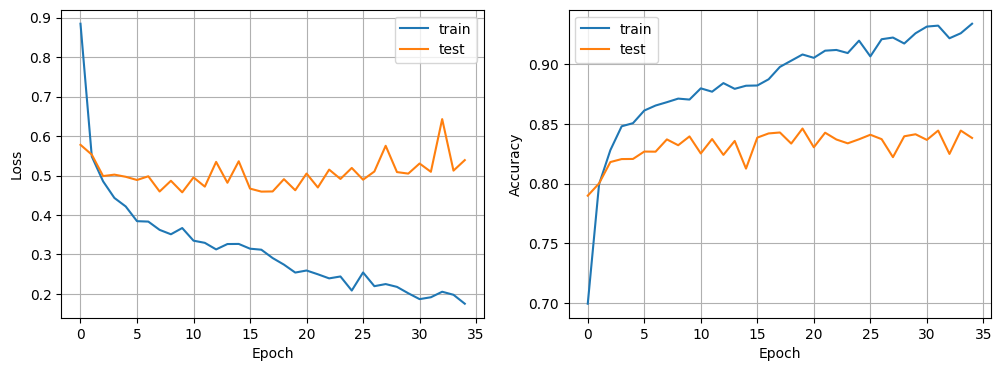

In [ ]:
model = FixedNeuralNetwork().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=7e-4, weight_decay=1e-4) # YOUR CODE HERE
loss_func = nn.CrossEntropyLoss() # YOUR CODE HERE

# Your experiments, come here
num_epochs = 35
train_losses_fixed, test_losses_fixed = [], []
train_accs_fixed, test_accs_fixed = [], []

for epoch in range(num_epochs):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in small_loader:
        images, labels = images.to(device), labels.to(device)
        opt.zero_grad()
        logits = model(images)
        loss = loss_func(logits, labels)
        loss.backward()
        opt.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    train_losses_fixed.append(total_loss / total)
    train_accs_fixed.append(correct / total)

    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += loss_func(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    test_losses_fixed.append(total_loss / total)
    test_accs_fixed.append(correct / total)
    print(f'Epoch {epoch+1:02d}: train acc={train_accs_fixed[-1]:.4f}, test acc={test_accs_fixed[-1]:.4f}')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses_fixed, label='train')
plt.plot(test_losses_fixed, label='test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(train_accs_fixed, label='train')
plt.plot(test_accs_fixed, label='test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

### Conclusions:
_Write down small report with your conclusions and your ideas._

В первой задаче использовалась полносвязная сеть с несколькими скрытыми слоями и оптимизатор Adam. Если увеличивать число нейронов, то модель лучше извлекает признаки из изображений.
Критерий качества - точность на тестовой выборке; целевое значение не менее 0.885.

Во второй задаче размер обучающей выборки уменьшен до 5000 объектов, а размер сети увеличен. Такая модель имеет достаточно параметров, чтобы хорошо запомнить обучающие примеры. Признак переобучения - дальнейшее уменьшение train loss при ухудшении или отсутствии улучшения test loss, а также разрыв между train и test accuracy.

В третьей задаче добавлены BatchNorm, Dropout и weight decay (AdamW). Dropout случайно отключает часть нейронов во время обучения, BatchNorm улучшает распределение активаций, а weight decay ограничивает рост весов. Эти методы должны уменьшить разрыв между обучающей и тестовой метриками, хотя могут немного замедлить обучение и снизить train accuracy.